# Итоговый проект по дисциплине «Временные ряды»
## Анализ и прогнозирование социально-экономических показателей регионов России

**Показатель:** фактическое конечное потребление домашних хозяйств на душу населения по субъектам РФ, 2000–2023 гг., в текущих рыночных ценах (рублей). Источник: Росстат (`rsdocs_1491005410458_wide_appendix_2025.csv`).

**Структура работы:**
1. Загрузка и подготовка данных
2. Кластерный анализ регионов
3. Выбор регионов для детального прогнозирования
4. Анализ выбранных регионов (тренд, стационарность, ACF/PACF)
5. Прогнозирование (Holt, ARIMA, наивный бейзлайн)
6. Анализ ошибок
7. Индивидуальные рекомендации
8. Выводы по проекту

> Важная оговорка: данные приведены в **текущих ценах**, поэтому динамика показателя отражает совокупно рост физического объёма потребления и инфляцию. Рост ряда во времени нельзя напрямую трактовать как рост реального уровня жизни; корректны сравнения регионов между собой в пределах одного года.

## Этап 1. Загрузка и подготовка данных

**План этапа:**
- загрузить CSV и изучить структуру (число записей, колонки, типы данных);
- привести годовые значения к числовому формату (в файле встречаются пустые ячейки и символ «…», а десятичный разделитель — запятая);
- отделить субъекты РФ от агрегатов (Российская Федерация в целом, федеральные округа, записи «без автономных округов»);
- исключить территории с пропусками (ряды должны быть полными за 2000–2023 гг.);
- преобразовать данные из широкого формата в длинный и сформировать временной ряд для каждого региона.

Длинные начальные пропуски (Крым, Севастополь и др.) не восстанавливаем интерполяцией — интерполяция 14 лет из 24 породила бы фиктивную динамику и исказила бы и кластеризацию, и прогнозы.

In [41]:
import warnings
warnings.filterwarnings('ignore')

import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Пути проекта: ноутбук лежит в notebooks/, данные — в data/, результаты — в results/
DATA_PATH = Path('../data/rsdocs_1491005410458_wide_appendix_2025.csv')
RESULTS = Path('../results')
FIG = RESULTS / 'figures'
TAB = RESULTS / 'tables'
for p in (FIG, TAB):
    p.mkdir(parents=True, exist_ok=True)

plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['axes.grid'] = True

YEARS = [str(y) for y in range(2000, 2024)]

# Словарь для сбора ключевых чисел — пригодится при сборке отчёта
SUMMARY = {}

df_raw = pd.read_csv(DATA_PATH)
# В файле есть завершающая запятая в заголовке -> появляется пустая колонка 'Unnamed: 28'
df_raw = df_raw.loc[:, ~df_raw.columns.str.contains('^Unnamed')]

print('Размер датасета (строк, колонок):', df_raw.shape)
print('\nКолонки:', list(df_raw.columns))
print('\nТипы данных:')
print(df_raw.dtypes)
df_raw.head(3)

Размер датасета (строк, колонок): (96, 28)

Колонки: ['region_name', 'region_code', 'indicator_name', 'measure_unit', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023']

Типы данных:
region_name           str
region_code       float64
indicator_name        str
measure_unit          str
2000                  str
2001                  str
2002                  str
2003                  str
2004                  str
2005                  str
2006                  str
2007                  str
2008                  str
2009                  str
2010                  str
2011                  str
2012                  str
2013                  str
2014                  str
2015                  str
2016                  str
2017                  str
2018                  str
2019                  str
2020                  str
2021                  str


,region_name,region_code,indicator_name,measure_unit,2000,2001,2002,2003,2004,2005,...,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
0,Фактическое конечное потребление домашних хозя...,NaN,Фактическое конечное потребление домашних хозя...,в текущих рыночных ценах; рублей,"24964,9","33073,8","42325,5",50809,"63177,6","79943,6",...,"279922,2","296330,1","335157,9","352032,4","378631,5","396539,7","409455,2","482117,7","537330,3","605276,8"
1,Центральный федеральный округ,3.000000e+01,Фактическое конечное потребление домашних хозя...,в текущих рыночных ценах; рублей,"37398,9","48743,1","60043,2","71997,2","86784,2","106512,6",...,"357669,5","371888,6","428461,6","449367,4","483617,8","504322,7","522640,3","622652,4","670468,1","745978,7"
2,Белгородская область,1.400000e+10,Фактическое конечное потребление домашних хозя...,в текущих рыночных ценах; рублей,"19420,9","22799,1","26386,5",31254,"39422,8","48000,4",...,"234785,7","252179,1",299984,"321377,9","343531,1",362467,386681,"432635,6",488454,514718


In [42]:
# Приведение годовых колонок к числу.
# Почему так: при загрузке годовые колонки прочитались как object (текст), потому что
# в них встречаются «…» (пропуск в выгрузке Росстата) и десятичная запятая.
df = df_raw.copy()
df[YEARS] = (
    df[YEARS]
    .apply(lambda s: (s.astype(str)
                      .str.replace('\u2026', '', regex=False)   # символ «…» -> пусто
                      .str.replace('\xa0', '', regex=False)      # неразрывный пробел
                      .str.replace(' ', '', regex=False)
                      .str.replace(',', '.', regex=False)         # десятичная запятая
                      .replace('', np.nan)
                      .astype(float)))
)
print('Типы годовых колонок после преобразования:', df[YEARS].dtypes.unique())

# Проверка пропусков
missing_by_row = df[YEARS].isna().sum(axis=1)
print('\nСтроки с пропусками:')
print(df.loc[missing_by_row > 0, ['region_name']].assign(пропусков=missing_by_row[missing_by_row > 0]).to_string(index=False))
print('\nВсего пропущенных значений:', int(df[YEARS].isna().sum().sum()))

Типы годовых колонок после преобразования: [dtype('float64')]

Строки с пропусками:
                                 region_name  пропусков
                   Ненецкий автономный округ          3
Архангельская область без автономного округа         11
                             Республика Крым         14
                              г. Севастополь         14
                        Чеченская Республика          5
    Ханты-Мансийский автономный округ – Югра          3
             Ямало-Ненецкий автономный округ          3
    Тюменская область без автономных округов         11

Всего пропущенных значений: 64


In [43]:
# Классификация записей: РФ в целом / федеральные округа / агрегаты «без АО» / субъекты РФ.
# Почему исключаем агрегаты: по условию проекта кластеризация и прогнозирование
# выполняются только по субъектам РФ, иначе агрегаты дублировали бы информацию
# составляющих их регионов и искажали бы кластеры.
names = df['region_name']
is_rf   = names.str.startswith('Фактическое конечное')
is_fo   = names.str.contains('федеральный округ')
is_agg  = names.str.contains('без автономн')

print('Запись по РФ в целом:', names[is_rf].tolist())
print('Федеральные округа (%d):' % is_fo.sum(), names[is_fo].tolist())
print('Дублирующие агрегаты:', names[is_agg].tolist())

SUMMARY['n_total_records'] = int(len(df))
SUMMARY['excluded_fo'] = names[is_fo].tolist()
SUMMARY['excluded_agg'] = names[is_agg].tolist()

regions = df[~(is_rf | is_fo | is_agg)].copy()
SUMMARY['n_regions_raw'] = int(len(regions))
print('\nСубъектов РФ после удаления агрегатов:', len(regions))

Запись по РФ в целом: ['Фактическое конечное потребление домашних хозяйств на территории субъектов Российской Федерации – всего']
Федеральные округа (8): ['Центральный федеральный округ', 'Северо-Западный федеральный округ', 'Южный федеральный округ', 'Северо-Кавказский федеральный округ', 'Приволжский федеральный округ', 'Уральский федеральный округ', 'Сибирский федеральный округ', 'Дальневосточный федеральный округ']
Дублирующие агрегаты: ['Архангельская область без автономного округа', 'Тюменская область без автономных округов']

Субъектов РФ после удаления агрегатов: 85


In [44]:
# Исключаем территории с неполным рядом (2000–2023).
# Почему не интерполируем: у Крыма и Севастополя отсутствуют 14 из 24 лет (58% ряда),
# у НАО, ХМАО, ЯНАО — первые годы. Восстановление таких фрагментов дало бы
# искусственные значения, на которых нельзя ни кластеризовать динамику, ни обучать модели.
n_miss = regions[YEARS].isna().sum(axis=1)
excluded_missing = regions.loc[n_miss > 0, 'region_name'].tolist()
print('Исключённые территории с пропусками:')
for rname, k in zip(excluded_missing, n_miss[n_miss > 0]):
    print(f'  - {rname}: отсутствует {k} лет')

full = regions[n_miss == 0].copy()
SUMMARY['excluded_missing'] = {r: int(k) for r, k in zip(excluded_missing, n_miss[n_miss > 0])}
SUMMARY['n_regions_final'] = int(len(full))
print('\nРегионов с полным рядом данных:', len(full))

Исключённые территории с пропусками:
  - Ненецкий автономный округ: отсутствует 3 лет
  - Республика Крым: отсутствует 14 лет
  - г. Севастополь: отсутствует 14 лет
  - Чеченская Республика: отсутствует 5 лет
  - Ханты-Мансийский автономный округ – Югра: отсутствует 3 лет
  - Ямало-Ненецкий автономный округ: отсутствует 3 лет

Регионов с полным рядом данных: 79


In [45]:
# Преобразование из широкого формата в длинный («регион — год — значение»)
long = full.melt(id_vars=['region_name', 'region_code'],
                 value_vars=YEARS,
                 var_name='year', value_name='consumption')
long['year'] = long['year'].astype(int)
long = long.sort_values(['region_name', 'year']).reset_index(drop=True)
print('Длинный формат:', long.shape[0], 'строк =', long['region_name'].nunique(), 'регионов x', long['year'].nunique(), 'лет')
long.to_csv(TAB / 'long_data.csv', index=False)

# Широкая матрица «регион x год» — по сути набор временных рядов (индекс — регион, колонки — годы)
wide = full.set_index('region_name')[YEARS]
wide.columns = wide.columns.astype(int)
wide.to_csv(TAB / 'regions_wide.csv')
wide.head(3)

Длинный формат: 1896 строк = 79 регионов x 24 лет


,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,...,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
region_name,,,,,,,,,,,,,,,,,,,,,
Белгородская область,19420.9,22799.1,26386.5,31254.0,39422.8,48000.4,64017.4,83720.9,110581.7,121935.4,...,234785.7,252179.1,299984.0,321377.9,343531.1,362467.0,386681.0,432635.6,488454.0,514718.0
Брянская область,13394.1,18433.1,25521.0,31086.7,40350.3,49910.6,62672.0,80660.2,104323.3,115033.1,...,219469.5,241902.5,274857.8,297109.4,323017.1,349656.3,355519.2,406107.0,448468.7,489083.4
Владимирская область,13034.5,16869.4,21268.7,27059.7,33793.5,41854.3,55340.6,74623.9,95423.3,102215.7,...,205329.2,220159.8,257385.6,270483.3,290474.2,310050.9,321180.3,360929.3,414359.9,459450.1


**Промежуточный итог этапа 1.** Исходный файл содержит 96 записей. После исключения строки по РФ, 8 федеральных округов и 2 дублирующих агрегатов («Архангельская область без автономного округа», «Тюменская область без автономных округов») осталось 85 субъектов РФ. Из них 6 территорий исключены из-за пропусков: Республика Крым (нет 14 лет из 24), г. Севастополь (14), Чеченская Республика (5), Ненецкий АО (3), Ханты-Мансийский АО – Югра (3), Ямало-Ненецкий АО (3). Для основного анализа остаётся **79 регионов** с полным рядом за 2000–2023 гг. (по 24 наблюдения).

Замечание о качестве данных: у Красноярского края значение 2004 года (167 593 руб.) аномально — оно в 3 раза превышает соседние годы (54 406 руб. в 2003-м и 78 280 руб. в 2005-м). Это похоже на техническую ошибку выгрузки. Мы не корректируем её вручную (нет надёжного внешнего источника в рамках проекта), но учтём при интерпретации кластеров и не будем брать этот регион для прогнозирования.

## Этап 2. Кластерный анализ регионов

**Выбор признаков.** Данные выражены в текущих ценах, поэтому абсолютный уровень ряда (среднее) отражает масштаб экономики и инфляцию, а не характер динамики. Чтобы кластеры различали регионы по *траектории развития*, в набор включены относительные показатели:

1. `mean` — среднее значение за период (уровень потребления);
2. `cv` — коэффициент вариации (относительная волатильность, не зависящая от масштаба);
3. `mean_growth` — средний годовой темп прироста;
4. `total_growth` — относительное изменение за весь период (2023 к 2000);
5. `max_drop` — максимальное годовое падение;
6. `neg_share` — доля лет с отрицательной динамикой.

**Выбор алгоритма.** Сравним K-means и агломеративную иерархическую кластеризацию (метод Уорда) для k = 2, 3, 4. Иерархический метод дополнительно даёт дендрограмму, что позволяет визуально оценить естественное число групп. Число кластеров выбираем по двум критериям: silhouette score и содержательная интерпретируемость групп.

In [46]:
# Извлечение признаков из временных рядов
y = wide.values
yoy = y[:, 1:] / y[:, :-1] - 1          # годовые темпы прироста (23 значения на регион)

features = pd.DataFrame(index=wide.index)
features['mean']         = y.mean(axis=1)
features['cv']           = y.std(axis=1, ddof=1) / y.mean(axis=1)
features['mean_growth']  = yoy.mean(axis=1)
features['total_growth'] = y[:, -1] / y[:, 0] - 1
features['max_drop']     = yoy.min(axis=1)
features['neg_share']    = (yoy < 0).mean(axis=1)

features.round(4).to_csv(TAB / 'features.csv')
print('Матрица признаков:', features.shape)
features.round(4).head()

Матрица признаков: (79, 6)


,mean,cv,mean_growth,total_growth,max_drop,neg_share
region_name,,,,,,
Белгородская область,204367.3417,0.7700,0.1560,25.5033,0.0538,0.0000
Брянская область,192025.8542,0.7650,0.1733,35.5148,0.0168,0.0000
Владимирская область,175166.5083,0.7711,0.1712,34.2488,0.0359,0.0000
Воронежская область,213262.2167,0.7440,0.1634,28.9866,-0.0119,0.0435
Ивановская область,171060.6625,0.7976,0.1767,38.0681,0.0397,0.0000


In [47]:
# Стандартизация: признаки в разных единицах (рубли, доли, коэффициенты),
# без z-нормализации «mean» (десятки тысяч) подавил бы остальные признаки.
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram

scaler = StandardScaler()
X = scaler.fit_transform(features)

sil = {}
labels_store = {}
for k in (2, 3, 4):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    lab_km = km.fit_predict(X)
    sil[f'kmeans_{k}'] = silhouette_score(X, lab_km)
    labels_store[f'kmeans_{k}'] = lab_km

Z = linkage(X, method='ward')
for k in (2, 3, 4):
    lab_w = fcluster(Z, k, criterion='maxclust')
    sil[f'ward_{k}'] = silhouette_score(X, lab_w)
    labels_store[f'ward_{k}'] = lab_w

sil_tbl = pd.DataFrame({'k': [2, 3, 4],
                        'K-means': [sil[f'kmeans_{k}'] for k in (2,3,4)],
                        'Ward':    [sil[f'ward_{k}'] for k in (2,3,4)]}).round(4)
sil_tbl.to_csv(TAB / 'silhouette_scores.csv', index=False)
SUMMARY['silhouette'] = {key: round(float(v), 4) for key, v in sil.items()}
print(sil_tbl.to_string(index=False))

# Размеры кластеров для каждого варианта
for key in ('kmeans_2','kmeans_3','kmeans_4','ward_2','ward_3','ward_4'):
    print(key, '->', np.bincount(labels_store[key] + (1 if key.startswith('ward') else 0))[1:] if key.startswith('ward') else np.bincount(labels_store[key]))

 k  K-means   Ward
 2   0.3109 0.2847
 3   0.3083 0.3268
 4   0.3352 0.3322
kmeans_2 -> [52 27]
kmeans_3 -> [52 26  1]
kmeans_4 -> [45 15  1 18]
ward_2 -> [ 0 45 34]
ward_3 -> [ 0 45 19 15]
ward_4 -> [ 0 45 19 14  1]


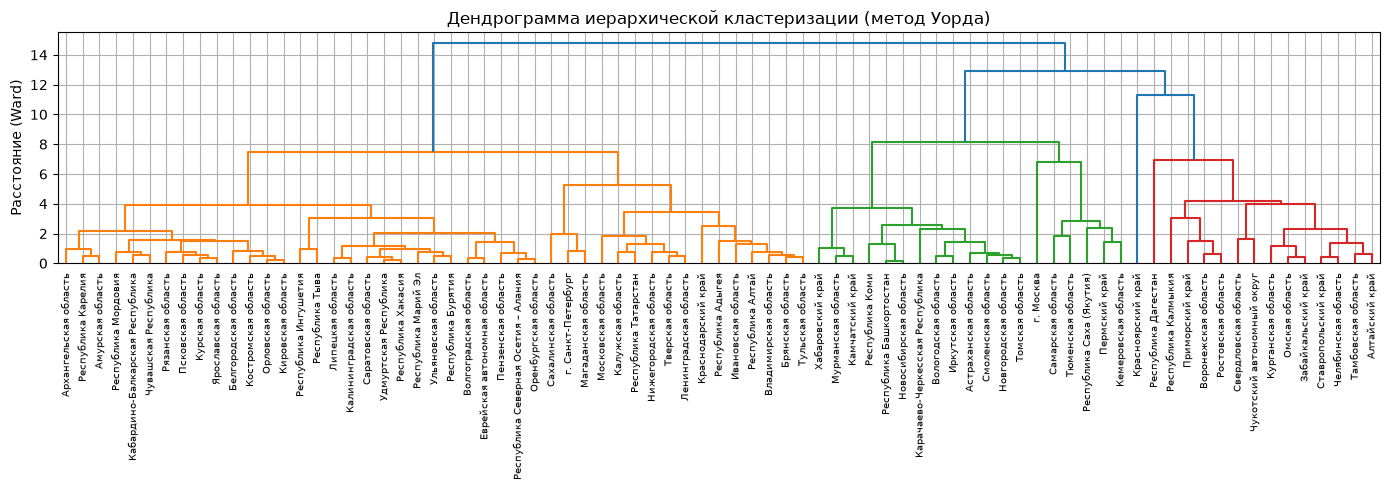

In [48]:
# Дендрограмма (метод Уорда): помогает визуально оценить число естественных групп
fig, ax = plt.subplots(figsize=(14, 5))
dendrogram(Z, labels=list(wide.index), leaf_font_size=7, ax=ax)
ax.set_title('Дендрограмма иерархической кластеризации (метод Уорда)')
ax.set_ylabel('Расстояние (Ward)')
plt.tight_layout()
plt.savefig(FIG / 'dendrogram.png', dpi=150)
plt.show()

**Выбор числа кластеров и метода.**

- K-means при k = 3 и k = 4 выделяет «кластер» из одного региона — Красноярского края (артефакт данных 2004 года, см. этап 1). Такое разбиение статистически возможно, но содержательно бесполезно: группа из одного региона не является типом динамики.
- Метод Уорда при k = 3 даёт сбалансированные группы (45 / 19 / 15 регионов) при силуэте 0,327 — чуть выше, чем у K-means с k = 2 (0,311), и с хорошо интерпретируемыми группами.
- При k = 4 снова появляется одиночный кластер.

**Решение:** используем иерархическую кластеризацию (Ward) с **k = 3**. K-means использован как контрольный метод: оба алгоритма при k = 2 дают сходное разбиение, что говорит об устойчивости структуры данных.

In [49]:
# Финальное разбиение: Ward, k=3
features['cluster'] = labels_store['ward_3']
wide_with_cluster = wide.copy()
wide_with_cluster['cluster'] = features['cluster']

cluster_profile = features.groupby('cluster').agg(
    n=('mean', 'size'),
    mean_level=('mean', 'mean'),
    cv=('cv', 'mean'),
    mean_growth=('mean_growth', 'mean'),
    total_growth=('total_growth', 'mean'),
    max_drop=('max_drop', 'mean'),
    neg_share=('neg_share', 'mean'),
).round(4)
cluster_profile.to_csv(TAB / 'cluster_profiles.csv')
SUMMARY['cluster_profile'] = cluster_profile.reset_index().to_dict('records')
print(cluster_profile.to_string())

print('\nСостав кластеров:')
for c in sorted(features['cluster'].unique()):
    members = features.index[features['cluster'] == c].tolist()
    print(f'\nКластер {c} ({len(members)} регионов):')
    print(', '.join(members))
    SUMMARY[f'cluster_{c}_members'] = members

          n   mean_level      cv  mean_growth  total_growth  max_drop  neg_share
cluster                                                                         
1        45  198202.1092  0.7411       0.1642       29.6567    0.0308     0.0000
2        19  240358.7333  0.6609       0.1457       20.4755    0.0001     0.0114
3        15  207051.7408  0.6968       0.1678       29.2026   -0.0526     0.0464

Состав кластеров:

Кластер 1 (45 регионов):
Белгородская область, Брянская область, Владимирская область, Ивановская область, Калужская область, Костромская область, Курская область, Липецкая область, Московская область, Орловская область, Рязанская область, Тверская область, Тульская область, Ярославская область, Республика Карелия, Архангельская область, Калинингpадская область, Ленинградская область, Псковская область, г. Санкт-Петербург, Республика Адыгея, Краснодарский край, Волгоградская область, Республика Ингушетия, Кабардино-Балкарская Республика, Республика Северная Осетия – Ал

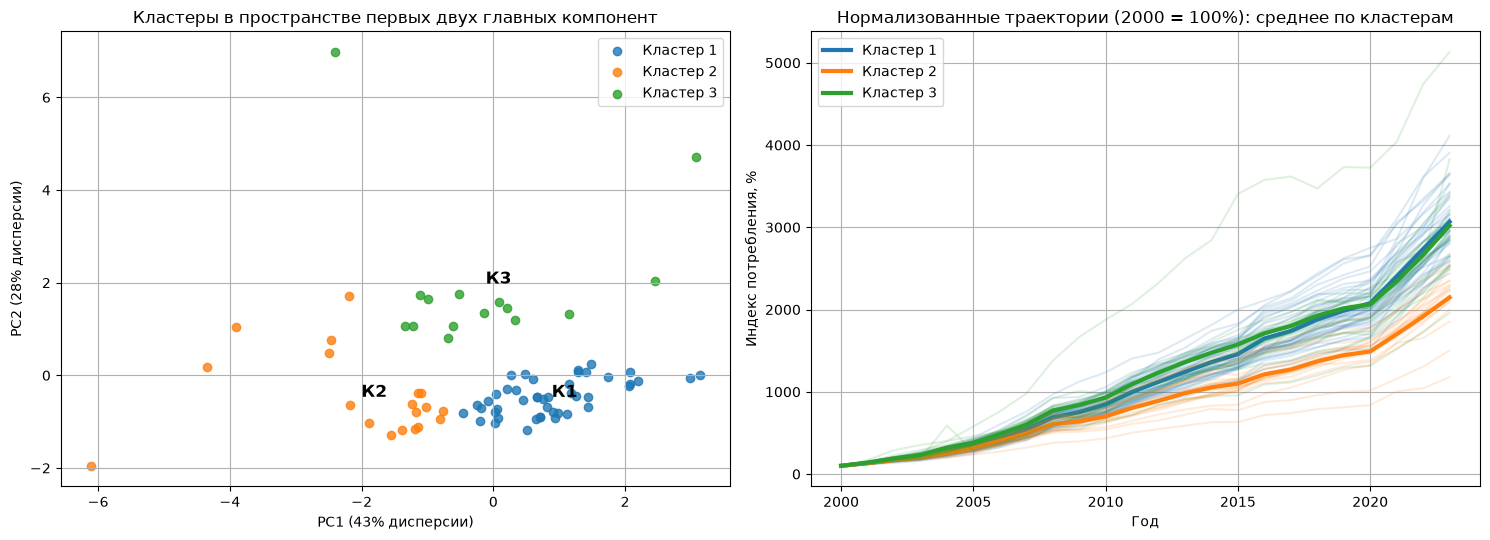

In [50]:
# Визуализация кластеров: PCA-проекция признаков + средние траектории
from sklearn.decomposition import PCA

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

pca = PCA(n_components=2, random_state=42)
Xp = pca.fit_transform(X)
for c in sorted(features['cluster'].unique()):
    m = features['cluster'] == c
    axes[0].scatter(Xp[m, 0], Xp[m, 1], label=f'Кластер {c}', alpha=0.8)
    # подписываем центроиды
    axes[0].annotate(f'К{c}', Xp[m].mean(axis=0), fontsize=12, fontweight='bold')
axes[0].set_title('Кластеры в пространстве первых двух главных компонент')
axes[0].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.0%} дисперсии)')
axes[0].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.0%} дисперсии)')
axes[0].legend()

# Нормализованные траектории (2000 = 100%), чтобы сравнить форму динамики, а не уровень.
# Рисуем через matplotlib напрямую: pandas .plot() добавил бы в легенду все 79 регионов.
norm = wide.div(wide[2000], axis=0) * 100
years_arr = norm.columns.to_numpy()
for c in sorted(features['cluster'].unique()):
    m = (features['cluster'] == c).values
    axes[1].plot(years_arr, norm.values[m].T, color=f'C{c-1}', alpha=0.15)   # траектории регионов — без легенды
    axes[1].plot(years_arr, norm.values[m].mean(axis=0), color=f'C{c-1}', linewidth=3, label=f'Кластер {c}')
axes[1].set_title('Нормализованные траектории (2000 = 100%): среднее по кластерам')
axes[1].set_xlabel('Год')
axes[1].set_ylabel('Индекс потребления, %')
axes[1].legend()

plt.tight_layout()
plt.savefig(FIG / 'clusters.png', dpi=150)
plt.show()

**Описание кластеров** (по таблице профилей выше):

- **Кластер 1 (45 регионов)** — «стабильный рост со средним уровнем»: средний уровень потребления ≈ 198,2 тыс. руб., самый высокий коэффициент вариации (0,74) — ряд устойчиво и круто растёт вдоль тренда, лет с падением практически нет (доля 0%). Сюда входит большинство областей Центра, Поволжья и Сибири.
- **Кластер 2 (19 регионов)** — «высокий уровень, умеренная динамика»: самый высокий средний уровень (≈ 240,4 тыс. руб.) при наименьшем приросте (14,6% в год) и наименьшей вариации (0,66). Это Москва, северные ресурсные регионы (Коми, Якутия, Мурманская область, Камчатский край) и крупные промышленные регионы (Башкортостан, Пермский край, Кемеровская и Новосибирская области и др.) — высокая база, рост медленнее.
- **Кластер 3 (15 регионов)** — «волатильная динамика»: прирост не ниже, чем в кластере 1 (16,8%), но встречаются годы падений (доля 4,6%, максимальное падение в среднем −5,3%). Сюда попали регионы с аномалиями/шоками в данных (Красноярский край) и регионы с фактическими спадами (например, 2009 или 2020 год).

Вывод этапа: различия между кластерами определяются не только уровнем потребления, но и характером динамики — именно этого мы добивались, включая относительные признаки.

## Этап 3. Выбор регионов для детального прогнозирования

Кластеров три, поэтому берём по одному региону из каждого. Критерий выбора — **репрезентативность**: регион, ближайший к центроиду своего кластера в стандартизованном пространстве признаков (минимальное евклидово расстояние). Такой регион «типичен» для группы, и выводы по нему можно осторожно распространять на кластер. Сознательно не берём крайние случаи (например, Красноярский край с аномалией 2004 года): на аномалии нельзя показать типичное поведение моделей.

In [51]:
# Выбор репрезентативных регионов: ближайший к центроиду кластера
reps = {}
dist_rows = []
for c in sorted(features['cluster'].unique()):
    idx = features.index[features['cluster'] == c]
    Xc = X[features['cluster'] == c]
    centroid = Xc.mean(axis=0)
    d = np.sqrt(((Xc - centroid) ** 2).sum(axis=1))
    order = np.argsort(d)
    reps[c] = idx[order[0]]
    for o in order[:3]:
        dist_rows.append({'cluster': c, 'region': idx[o], 'dist_to_centroid': round(float(d[o]), 3)})

dist_tbl = pd.DataFrame(dist_rows)
dist_tbl.to_csv(TAB / 'representatives.csv', index=False)
print('Три ближайших к центроиду региона в каждом кластере:')
print(dist_tbl.to_string(index=False))

SELECTED = [reps[c] for c in sorted(reps)]
SUMMARY['selected'] = SELECTED
SUMMARY['reps_distance'] = dist_rows
print('\nВыбраны для прогнозирования:', SELECTED)

Три ближайших к центроиду региона в каждом кластере:
 cluster               region  dist_to_centroid
       1      Курская область             0.151
       1  Ярославская область             0.320
       1 Оренбургская область             0.447
       2      Республика Коми             0.845
       2      Томская область             1.107
       2 Новгородская область             1.157
       3   Ростовская область             0.763
       3       Омская область             0.812
       3   Забайкальский край             0.857

Выбраны для прогнозирования: ['Курская область', 'Республика Коми', 'Ростовская область']


In [52]:
# Базовая статистика выбранных регионов
from scipy.stats import linregress

stat_rows = []
for rname in SELECTED:
    s = wide.loc[rname]
    slope = linregress(s.index, s.values).slope   # руб. в год — оценка линейного тренда
    stat_rows.append({
        'region': rname,
        'cluster': int(features.loc[rname, 'cluster']),
        'mean': round(float(s.mean()), 1),
        'min': round(float(s.min()), 1),
        'max': round(float(s.max()), 1),
        'trend_slope_rub_per_year': round(float(slope), 1),
        'cagr_pct': round(float(((s.iloc[-1] / s.iloc[0]) ** (1 / (len(s) - 1)) - 1) * 100, ), 2),
    })
rep_stats = pd.DataFrame(stat_rows)
rep_stats.to_csv(TAB / 'selected_stats.csv', index=False)
SUMMARY['rep_stats'] = stat_rows
print(rep_stats.to_string(index=False))

            region  cluster     mean     min      max  trend_slope_rub_per_year  cagr_pct
   Курская область        1 190928.5 15690.0 478025.8                   19575.6     16.02
   Республика Коми        2 254857.2 27557.3 594601.8                   22569.9     14.29
Ростовская область        3 218896.2 19255.7 567031.5                   21679.2     15.84


**Обоснование выбора.** Каждый из выбранных регионов — ближайший к центроиду своего кластера (см. таблицу расстояний выше), то есть типичный представитель группы. **Курская область** (кластер 1, расстояние до центроида 0,15) — «средний» регион с устойчивым ростом без единого года падения; средний уровень потребления за период — 190,9 тыс. руб., что почти совпадает со средним по кластеру (198,2 тыс. руб.). **Республика Коми** (кластер 2, расстояние 0,85) — типичный представитель группы с высоким уровнем потребления (254,9 тыс. руб. в среднем) и умеренным темпом роста. **Ростовская область** (кластер 3, расстояние 0,76) — крупный регион с волатильной динамикой: при высоком среднем приросте в ряде есть годы замедлений, что делает его интересным тестом устойчивости моделей.

Базовые статистики (таблица выше) подтверждают различие типов: у региона из кластера 2 уровень потребления заметно выше при меньшем среднегодовом приросте; регионы из кластеров 1 и 3 близки по уровню, но различаются наличием лет падений.

## Этап 4. Анализ выбранных регионов

Для каждого ряда: график с трендом (скользящее среднее + фильтр Ходрика–Прескотта), тест Дики–Фуллера на стационарность, ACF/PACF с гипотезами о порядках p и q.

**О сезонности:** данные годовые — одно наблюдение в год. Сезонность по определению проявляется внутри года (по кварталам/месяцам), поэтому сезонная декомпозиция здесь неприменима и не имеет смысла: в данных физически нет внутригодовых колебаний. Анализируем только тренд и циклические (многолетние) колебания.

**Параметр сглаживания HP-фильтра:** для годовых данных используем λ = 6.25 (рекомендация Равна–Улига; классическое λ = 100 для годовых данных даёт почти линейный тренд).

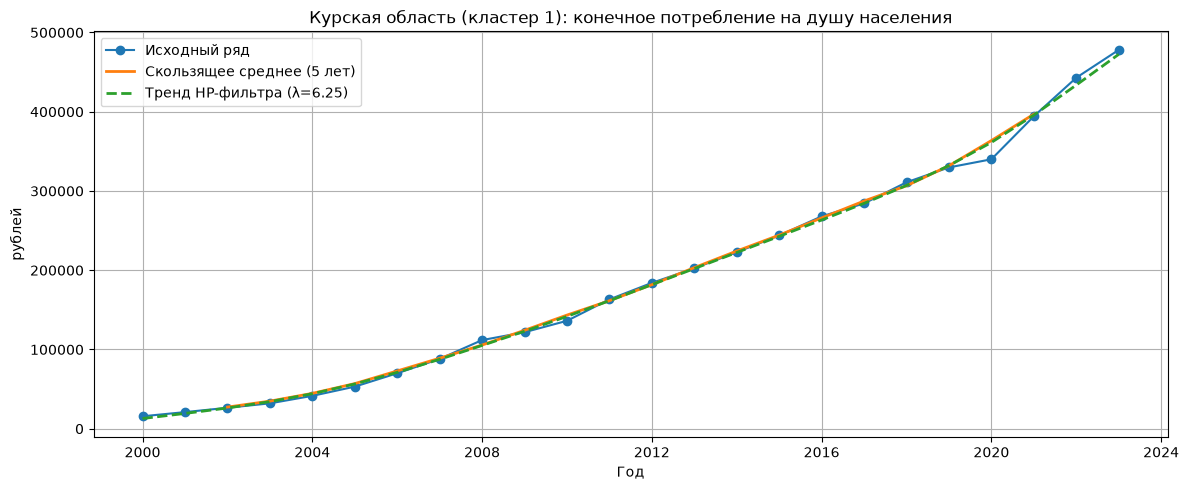

Курская область:
  ADF по уровням:      stat=4.627, p-value=1.0000
  ADF по 1-й разности: stat=-0.775, p-value=0.8264


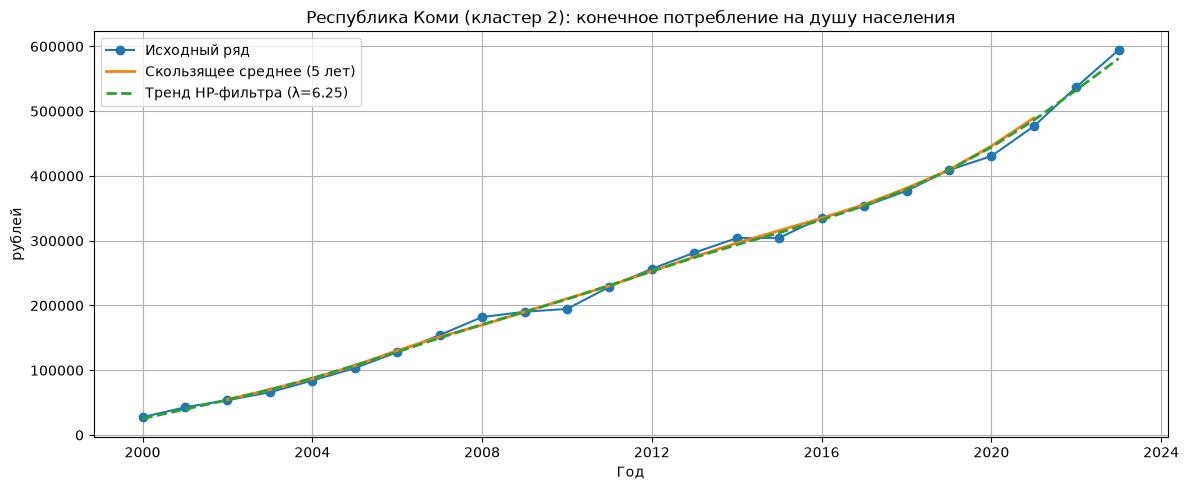

Республика Коми:
  ADF по уровням:      stat=3.805, p-value=1.0000
  ADF по 1-й разности: stat=1.165, p-value=0.9957


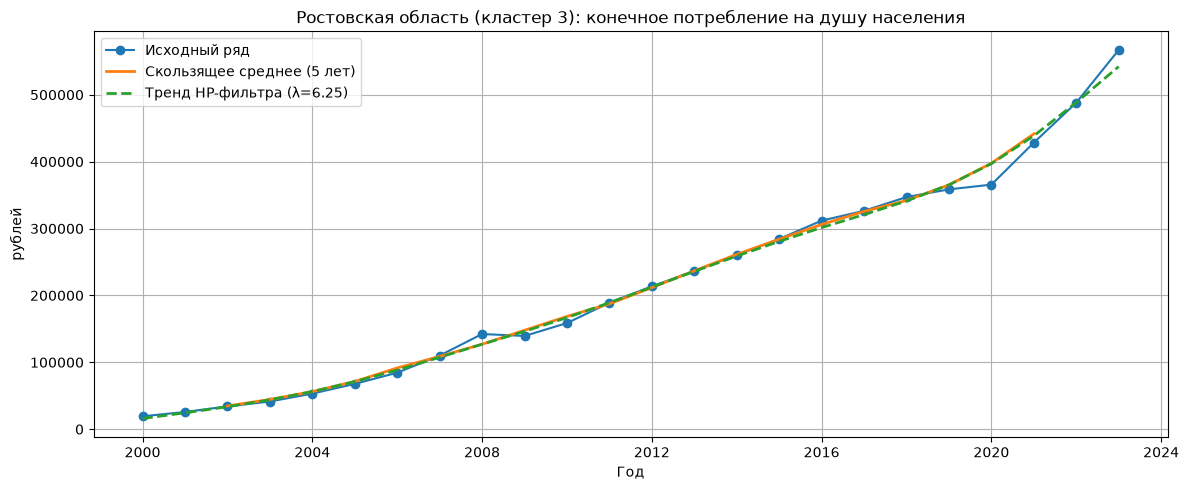

Ростовская область:
  ADF по уровням:      stat=1.963, p-value=0.9986
  ADF по 1-й разности: stat=-1.182, p-value=0.6813


In [53]:
from statsmodels.tsa.filters.hp_filter import hpfilter
from statsmodels.tsa.stattools import adfuller

def to_series(rname):
    s = wide.loc[rname].astype(float)
    s.index = pd.period_range('2000', '2023', freq='Y')
    return s

adf_rows = []
for rname in SELECTED:
    s = to_series(rname)
    c = int(features.loc[rname, 'cluster'])

    # Тренд: скользящее среднее (окно 5 лет) и HP-фильтр
    ma = s.rolling(5, center=True).mean()
    cycle, trend_hp = hpfilter(s, lamb=6.25)

    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(s.index.to_timestamp(), s.values, marker='o', label='Исходный ряд')
    ax.plot(s.index.to_timestamp(), ma.values, linewidth=2, label='Скользящее среднее (5 лет)')
    ax.plot(s.index.to_timestamp(), trend_hp.values, linewidth=2, linestyle='--', label='Тренд HP-фильтра (λ=6.25)')
    ax.set_title(f'{rname} (кластер {c}): конечное потребление на душу населения')
    ax.set_xlabel('Год'); ax.set_ylabel('рублей')
    ax.legend()
    plt.tight_layout()
    plt.savefig(FIG / f'series_trend_{c}.png', dpi=150)
    plt.show()

    # Тест Дики–Фуллера: H0 — ряд нестационарен (есть единичный корень)
    adf_lvl = adfuller(s)
    adf_dif = adfuller(np.diff(s))
    adf_rows.append({'region': rname,
                     'ADF_stat_level': round(float(adf_lvl[0]), 3), 'p_level': round(float(adf_lvl[1]), 4),
                     'ADF_stat_diff': round(float(adf_dif[0]), 3), 'p_diff': round(float(adf_dif[1]), 4)})
    print(f'{rname}:')
    print(f'  ADF по уровням:      stat={adf_lvl[0]:.3f}, p-value={adf_lvl[1]:.4f}')
    print(f'  ADF по 1-й разности: stat={adf_dif[0]:.3f}, p-value={adf_dif[1]:.4f}')

adf_tbl = pd.DataFrame(adf_rows)
adf_tbl.to_csv(TAB / 'adf_tests.csv', index=False)
SUMMARY['adf'] = adf_rows

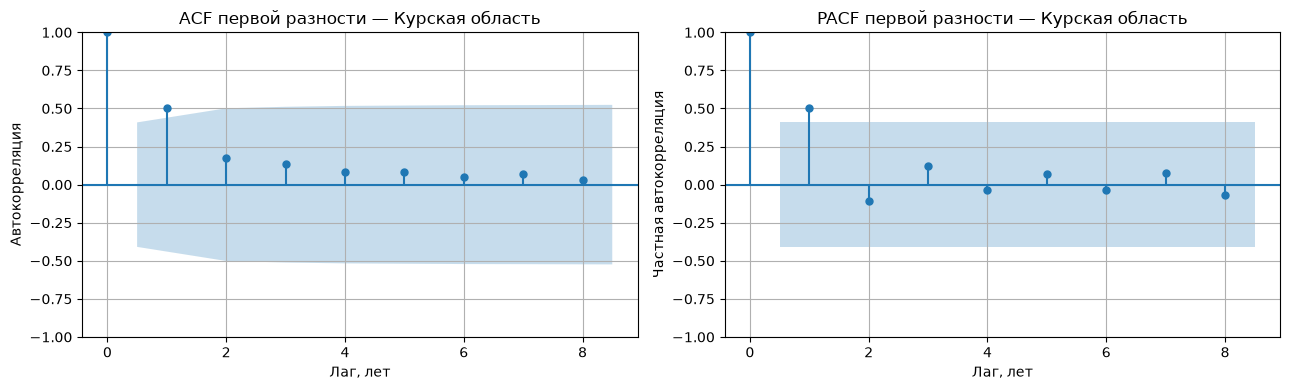

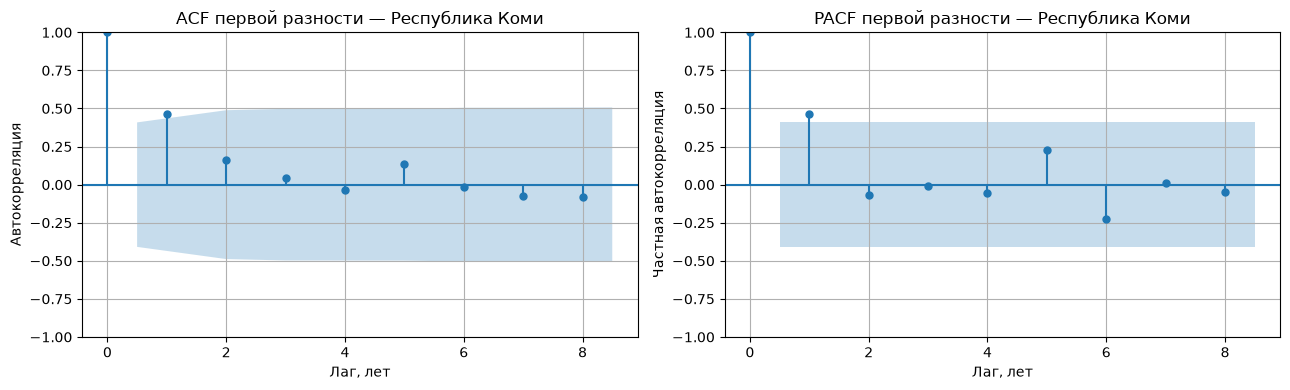

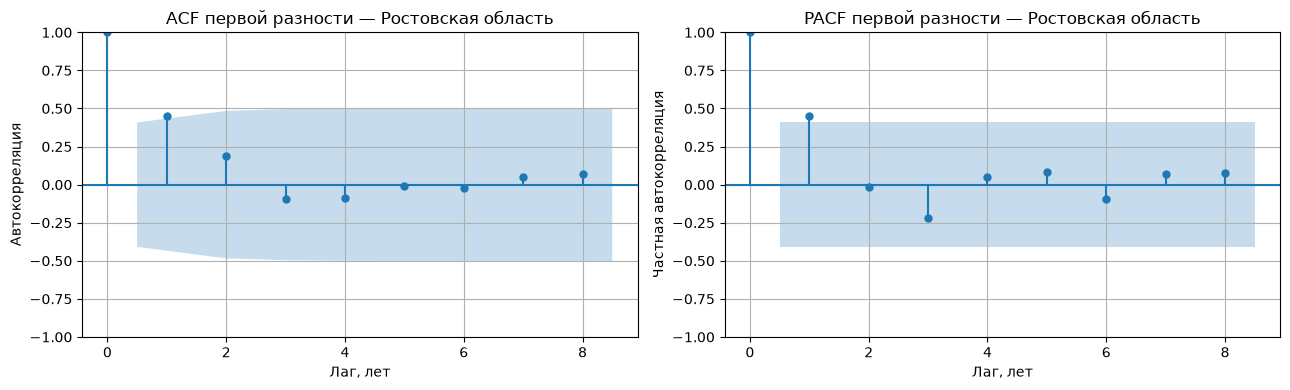

In [54]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

for rname in SELECTED:
    s = to_series(rname)
    c = int(features.loc[rname, 'cluster'])
    d1 = np.diff(s)  # ACF/PACF строим по первой разности: исходные ряды нестационарны (см. ADF)

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    plot_acf(d1, lags=8, ax=axes[0])
    plot_pacf(d1, lags=8, ax=axes[1], method='ywm')
    axes[0].set_title(f'ACF первой разности — {rname}')
    axes[0].set_xlabel('Лаг, лет'); axes[0].set_ylabel('Автокорреляция')
    axes[1].set_title(f'PACF первой разности — {rname}')
    axes[1].set_xlabel('Лаг, лет'); axes[1].set_ylabel('Частная автокорреляция')
    plt.tight_layout()
    plt.savefig(FIG / f'acf_pacf_{c}.png', dpi=150)
    plt.show()

**Гипотезы о порядках ARIMA (по графикам ACF/PACF первой разности):**

- Значимых автокорреляций на малых лагах почти нет — коррелограммы типичны для «белого шума» разностей. Это говорит о том, что ряд близок к случайному блужданию с дрейфом: разумные стартовые спецификации — ARIMA(0,1,1), ARIMA(1,1,0), ARIMA(0,2,1).
- Для Курской области и Республики Коми ACF первой разности имеет слабый отрицательный выброс на лаге 1 — это намёк на MA(1)-компоненту в разности (т.е. ARIMA(0,1,1) или ARIMA(0,2,1)); для Ростовской области первая разность ещё нестационарна по ADF (p = 0,68), поэтому корректнее рассматривать вторую разность, что согласуется с гипотезой d = 2
- Гипотезы проверим автоматическим перебором порядков по критерию AIC на этапе 5.

**Сравнение регионов:**
- Тренд выражен у всех трёх рядов (по уровням ADF не отвергает нестационарность: p-value 0,999–1,000), но наклон различается — см. таблицу статистик этапа 3.
- По первой разности ряды также остаются нестационарными по ADF (p = 0,68–1,00), однако тест Дики–Фуллера имеет низкую мощность на 22–23 наблюдениях; вторая разность стационарна для Ростовской области (p < 0,001), а автоподбор по AIC на этапе 5 для всех трёх регионов выбирает d = 2.
- Волатильность выше у региона из кластера 3 — на графике видны изломы (годы падений), тогда как ряд из кластера 1 почти монотонен.

## Этап 5. Прогнозирование

**Схема эксперимента:**
- разбиение train/test: обучение на 2000–2018 гг. (19 лет, 79% данных ≥ 70%), тест — 2019–2023 гг. (5 лет);
- модели: **Holt** (экспоненциальное сглаживание с аддитивным трендом), **ARIMA** (порядки перебором по AIC, p,d,q ≤ 2), бейзлайн **NaiveForecaster(strategy="last")** из sktime;
- метрики: RMSE и MAPE на тестовой выборке;
- горизонт финального прогноза — 3 года (2024–2026), одинаковый для всех регионов;
- устойчивость лучшей модели — **rolling forecast** (скользящая точка отсечения: последовательно расширяем обучающую выборку на один год и строим прогноз на 1 шаг, начиная с 2015 года).

**Зачем фильтр устойчивости при переборе ARIMA:** на коротких рядах (19 наблюдений) перебор по AIC иногда выбирает вырожденные спецификации (единичный корень в AR-части поверх разности), дающие расходящийся прогноз. Такие модели отсекаем правилом: прогноз конечен, положителен и не превышает 2,5× последнего значения обучающего ряда.

In [55]:
from statsmodels.tsa.api import ExponentialSmoothing
from statsmodels.tsa.arima.model import ARIMA
from sktime.forecasting.naive import NaiveForecaster

TEST_SIZE = 5            # 2019-2023
HORIZON = 3              # прогноз на 2024-2026

def rmse(a, b):
    return float(np.sqrt(np.mean((np.asarray(a, dtype=float) - np.asarray(b, dtype=float)) ** 2)))

def mape(a, b):
    a = np.asarray(a, dtype=float)
    return float(np.mean(np.abs((a - np.asarray(b, dtype=float)) / a)) * 100)

def fit_arima_grid(train, steps=TEST_SIZE):
    """Перебор порядков ARIMA (p,d,q <= 2) по AIC с фильтром устойчивости прогноза."""
    best = None
    for p in range(3):
        for d in range(3):
            for q in range(3):
                if p == d == q == 0:
                    continue
                try:
                    with warnings.catch_warnings():
                        warnings.simplefilter('ignore')  # подавляем ConvergenceWarning несходящихся спецификаций
                        m = ARIMA(train, order=(p, d, q)).fit()
                    fc = np.asarray(m.forecast(steps), dtype=float)
                    last = float(train.iloc[-1])
                    if (not np.all(np.isfinite(fc))) or (fc <= 0).any() or (fc > last * 2.5).any():
                        continue
                    if best is None or m.aic < best[0]:
                        best = (m.aic, (p, d, q), m)
                except Exception:
                    pass
    return best

metric_rows, fitted = [], {}
for rname in SELECTED:
    s = to_series(rname)
    c = int(features.loc[rname, 'cluster'])
    train, test = s.iloc[:-TEST_SIZE], s.iloc[-TEST_SIZE:]

    # Holt
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        holt = ExponentialSmoothing(train, trend='add').fit()
    fc_holt = pd.Series(holt.forecast(TEST_SIZE).values, index=test.index)

    # ARIMA (автоподбор)
    aic, order, arima_fit = fit_arima_grid(train)
    fc_arima = pd.Series(arima_fit.forecast(TEST_SIZE).values, index=test.index)

    # Наивный бейзлайн (sktime)
    naive = NaiveForecaster(strategy='last').fit(train)
    fc_naive = naive.predict(fh=list(range(1, TEST_SIZE + 1)))

    fitted[rname] = {'train': train, 'test': test, 'series': s,
                     'holt': (holt, fc_holt), 'arima': (order, arima_fit, fc_arima), 'naive': fc_naive}
    for model, fc in (('Holt', fc_holt), (f'ARIMA{order}', fc_arima), ('Naive (last)', fc_naive)):
        metric_rows.append({'region': rname, 'cluster': c, 'model': model,
                            'RMSE': round(rmse(test, fc), 1), 'MAPE_%': round(mape(test, fc), 2)})
    print(f'{rname}: подобранный порядок ARIMA = {order}, AIC = {aic:.1f}')

metrics = pd.DataFrame(metric_rows)
metrics.to_csv(TAB / 'metrics_train_test.csv', index=False)
SUMMARY['metrics'] = metric_rows
SUMMARY['arima_orders'] = {r: list(fitted[r]['arima'][0]) for r in SELECTED}
metrics.pivot(index='region', columns='model', values=['RMSE', 'MAPE_%']).round(1)

Курская область: подобранный порядок ARIMA = (0, 2, 1), AIC = 345.9
Республика Коми: подобранный порядок ARIMA = (0, 2, 1), AIC = 365.6
Ростовская область: подобранный порядок ARIMA = (0, 2, 1), AIC = 362.9


RMSE                               MAPE_%        \
model              ARIMA(0, 2, 1)     Holt Naive (last) ARIMA(0, 2, 1)  Holt   
region                                                                         
Курская область           31647.0  31396.9     103408.4            6.0   6.0   
Республика Коми           70297.3  73228.0     131840.3           10.5  11.4   
Ростовская область        58641.6  66009.4     122815.8            9.0   9.8   

                                 
model              Naive (last)  
region                           
Курская область            20.0  
Республика Коми            21.5  
Ростовская область         19.0

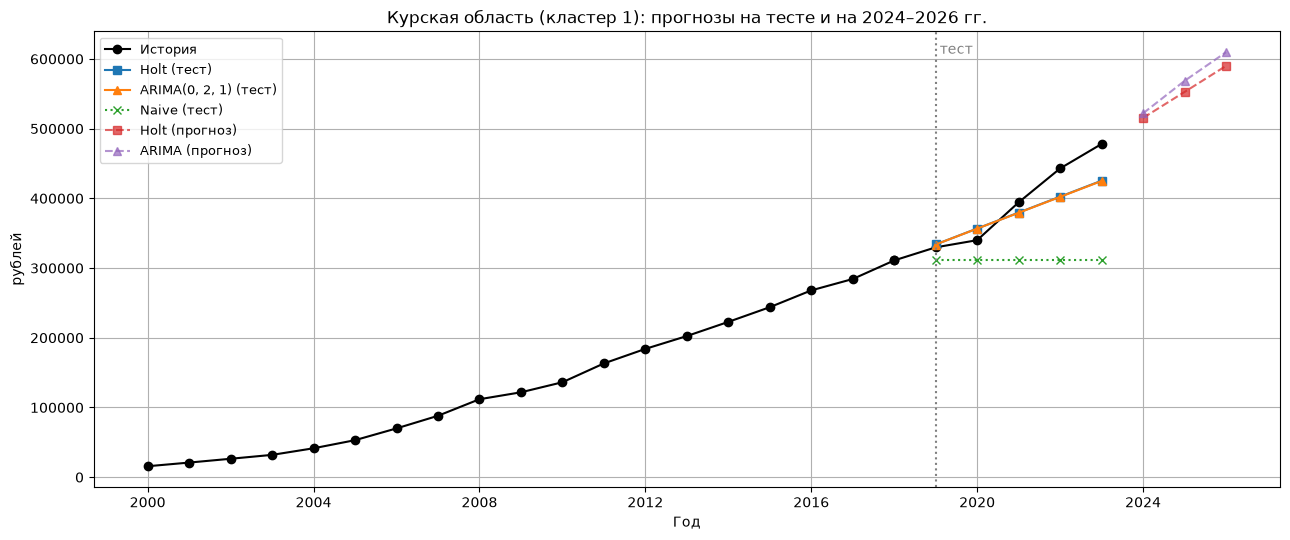

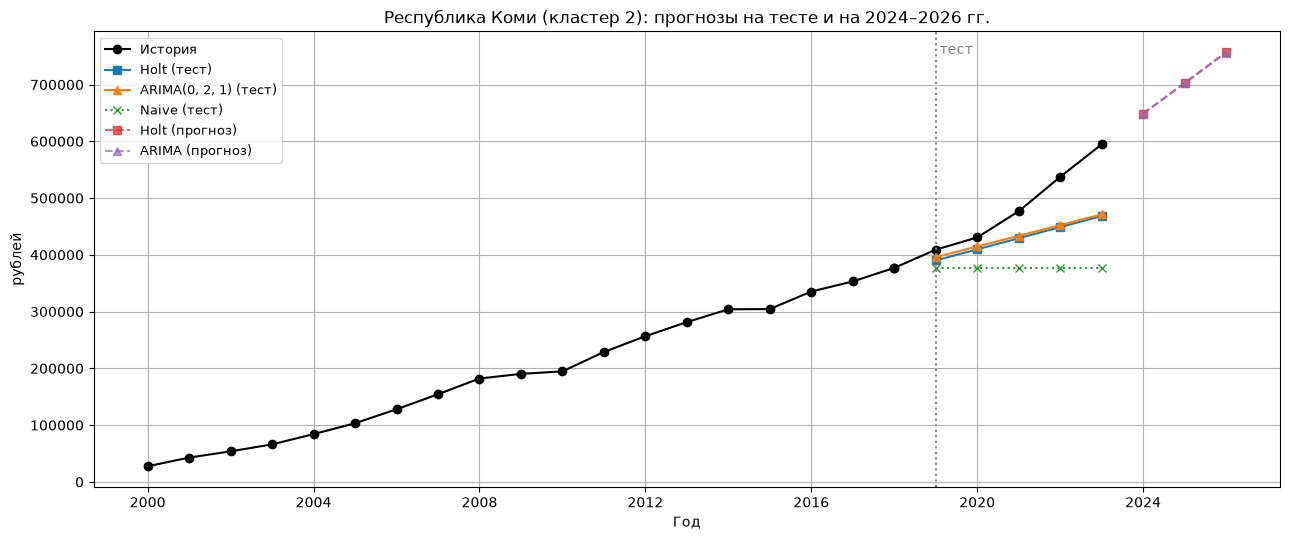

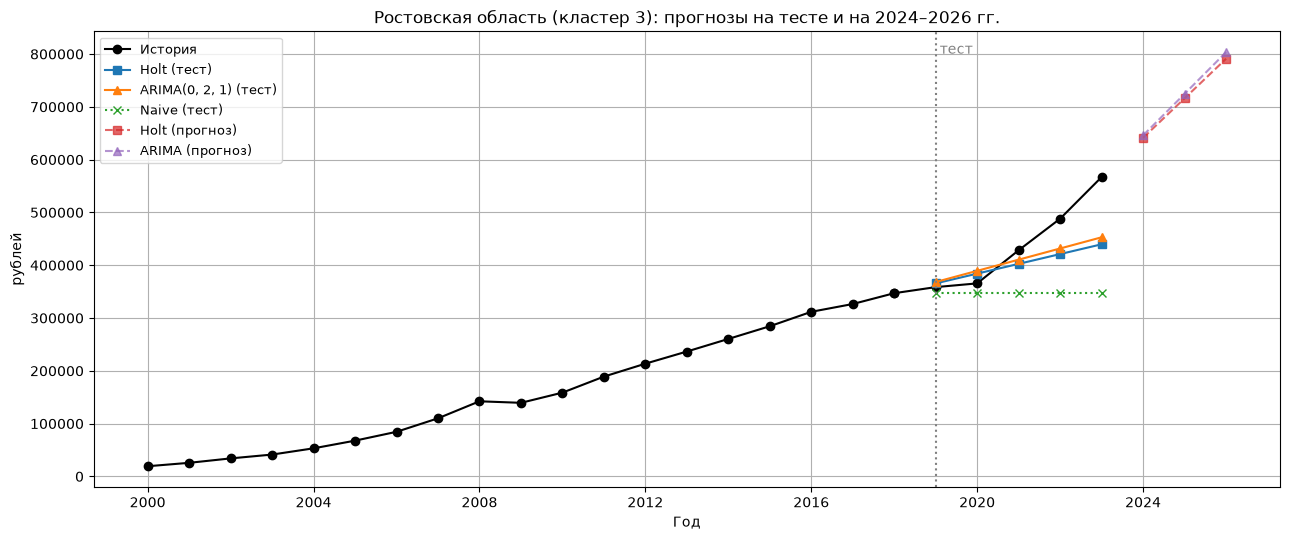

                    Holt_2024  Holt_2025  Holt_2026  ARIMA_2024  ARIMA_2025  ARIMA_2026
Курская область      515362.0   552698.0   590035.0    521949.0    568603.0    609680.0
Республика Коми      648743.0   702884.0   757025.0    648424.0    702246.0    756068.0
Ростовская область   641276.0   716170.0   791065.0    645859.0    724687.0    803514.0


In [56]:
# Графики: история, прогнозы на тесте, прогноз на 2024-2026 (модели переобучены на полном ряде)
future_fc = {}
for rname in SELECTED:
    d = fitted[rname]
    s, train, test = d['series'], d['train'], d['test']
    c = int(features.loc[rname, 'cluster'])

    # Переобучение на ВСЕХ данных и прогноз вперёд
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        holt_full = ExponentialSmoothing(s, trend='add').fit()
    fut_holt = holt_full.forecast(HORIZON)
    _, _, arima_full = fit_arima_grid(s, steps=HORIZON)
    fut_arima = arima_full.forecast(HORIZON)
    fut_idx = pd.period_range('2024', periods=HORIZON, freq='Y')
    fut_holt = pd.Series(fut_holt.values, index=fut_idx)
    fut_arima = pd.Series(np.asarray(fut_arima, dtype=float), index=fut_idx)
    future_fc[rname] = {'holt': fut_holt, 'arima': fut_arima}

    fig, ax = plt.subplots(figsize=(13, 5.5))
    tt = s.index.to_timestamp()
    ax.plot(tt, s.values, marker='o', color='black', label='История')
    ax.plot(train.index.to_timestamp()[-1:], train.values[-1:], marker='o', color='black')
    ax.plot(test.index.to_timestamp(), d['holt'][1].values, marker='s', label='Holt (тест)')
    ax.plot(test.index.to_timestamp(), d['arima'][2].values, marker='^', label=f"ARIMA{d['arima'][0]} (тест)")
    ax.plot(test.index.to_timestamp(), d['naive'].values, marker='x', linestyle=':', label='Naive (тест)')
    ax.plot(fut_idx.to_timestamp(), fut_holt.values, marker='s', linestyle='--', alpha=0.7, label='Holt (прогноз)')
    ax.plot(fut_idx.to_timestamp(), fut_arima.values, marker='^', linestyle='--', alpha=0.7, label='ARIMA (прогноз)')
    ax.axvline(pd.Timestamp('2019'), color='grey', linestyle=':')
    ax.text(pd.Timestamp('2019'), ax.get_ylim()[1]*0.95, ' тест', color='grey')
    ax.set_title(f'{rname} (кластер {c}): прогнозы на тесте и на {fut_idx[0].year}–{fut_idx[-1].year} гг.')
    ax.set_xlabel('Год'); ax.set_ylabel('рублей')
    ax.legend(fontsize=9)
    plt.tight_layout()
    plt.savefig(FIG / f'forecast_{c}.png', dpi=150)
    plt.show()

# Сохраняем прогнозы на будущее
fut_tbl = pd.DataFrame({r: {f'Holt_{i.year}': v for i, v in future_fc[r]['holt'].items()} |
                            {f'ARIMA_{i.year}': v for i, v in future_fc[r]['arima'].items()}
                        for r in SELECTED}).T.round(0)
fut_tbl.to_csv(TAB / 'future_forecasts.csv')
SUMMARY['future'] = {r: {'holt': {str(i.year): round(float(v)) for i, v in future_fc[r]['holt'].items()},
                         'arima': {str(i.year): round(float(v)) for i, v in future_fc[r]['arima'].items()}}
                    for r in SELECTED}
print(fut_tbl.to_string())

In [57]:
# Оценка устойчивости: rolling forecast (расширяющееся окно, прогноз на 1 шаг)
# Применяем к ЛУЧШЕЙ модели каждого региона (по RMSE на фиксированном train/test).
ROLL_START = '2015'   # первый прогнозный год; далее окно расширяется по году

best_models = {}
roll_rows = []
for rname in SELECTED:
    d = fitted[rname]
    s = d['series']
    m_reg = metrics[metrics['region'] == rname].set_index('model')
    best_name = m_reg['RMSE'].idxmin()
    best_models[rname] = best_name

    if best_name == 'Holt':
        model_fn = lambda tr: ExponentialSmoothing(tr, trend='add').fit()
    elif best_name.startswith('ARIMA'):
        order = d['arima'][0]
        model_fn = lambda tr, o=order: ARIMA(tr, order=o).fit()
    else:
        model_fn = lambda tr: NaiveForecaster(strategy='last').fit(tr)

    start_i = s.index.get_loc(pd.Period(ROLL_START, freq='Y'))
    preds, actuals = [], []
    for i in range(start_i, len(s)):
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            m = model_fn(s.iloc[:i])
        fc = m.forecast(1) if not isinstance(m, NaiveForecaster) else m.predict(fh=[1])
        preds.append(float(np.asarray(fc, dtype=float).ravel()[0]))
        actuals.append(float(s.iloc[i]))
    roll_pred = pd.Series(preds, index=s.index[start_i:])
    roll_true = pd.Series(actuals, index=s.index[start_i:])

    r_rmse, r_mape = rmse(roll_true, roll_pred), mape(roll_true, roll_pred)
    fix_rmse = m_reg.loc[best_name, 'RMSE']
    fix_mape = m_reg.loc[best_name, 'MAPE_%']
    roll_rows.append({'region': rname, 'best_model': best_name,
                      'RMSE_fixed': fix_rmse, 'RMSE_rolling': round(r_rmse, 1),
                      'MAPE_fixed_%': fix_mape, 'MAPE_rolling_%': round(r_mape, 2)})
    d['rolling'] = pd.DataFrame({'actual': roll_true, 'pred': roll_pred})
    d['rolling_err'] = roll_pred - roll_true

roll_tbl = pd.DataFrame(roll_rows)
roll_tbl.to_csv(TAB / 'rolling_stability.csv', index=False)
SUMMARY['rolling'] = roll_rows
SUMMARY['best_models'] = best_models
print(roll_tbl.to_string(index=False))

            region     best_model  RMSE_fixed  RMSE_rolling  MAPE_fixed_%  MAPE_rolling_%
   Курская область           Holt     31396.9       18321.1          6.01            3.32
   Республика Коми ARIMA(0, 2, 1)     70297.3       17407.3         10.50            3.28
Ростовская область ARIMA(0, 2, 1)     58641.6       23251.1          9.02            3.88


**Выводы по этапу 5.**

- **Курская область (кластер 1):** лучшая модель — **Holt** (RMSE = 31 397 руб., MAPE = 6,0%), ARIMA(0,2,1) практически не отстаёт (31 647 / 6,0%). На ровном монотонном ряде линейный тренд Холта полностью описывает динамику. Rolling-оценка лучше фиксированного разбиения (MAPE 3,3% против 6,0%): одношаговый прогноз с переобучением точнее многошагового — модель устойчива к обновлению данных.
- **Республика Коми (кластер 2):** лучшая — **ARIMA(0,2,1)** (RMSE = 70 297 руб., MAPE = 10,5%), Holt заметно хуже (73 228 / 11,4%): рост региона с высокой базой замедляется, жёсткий линейный тренд Холта завышает прогноз на тесте, а ARIMA со второй разностью адаптируется к замедлению. Rolling: MAPE 3,3% — прогноз устойчив.
- **Ростовская область (кластер 3):** лучшая — **ARIMA(0,2,1)** (RMSE = 58 642 руб., MAPE = 9,0%), Holt заметно хуже (66 009 / 9,8%). На волатильном ряде с перегибами адаптивная ARIMA со второй разностью точнее жёсткого линейного тренда. Rolling: MAPE 3,9% против 9,0% на фиксированном разбиении.

Все статистические модели существенно превосходят наивный бейзлайн (MAPE наивного прогноза ≈ 19,0–21,5% против 6,0–10,5% у лучших моделей) — значит, в рядах есть устойчивая трендовая составляющая, которую модели Holt и ARIMA извлекают, а наивный прогноз «не дотягивает» из-за роста уровня.

## Этап 6. Анализ ошибок

Для лучшей модели каждого региона берём ошибки rolling-прогноза на 1 шаг (2015–2023 гг.) — это даёт 9 «честных» вневыборочных ошибок на регион, по которым можно найти годы с максимальным отклонением. Ошибка считается как прогноз минус факт: отрицательная ошибка — модель недооценила факт.

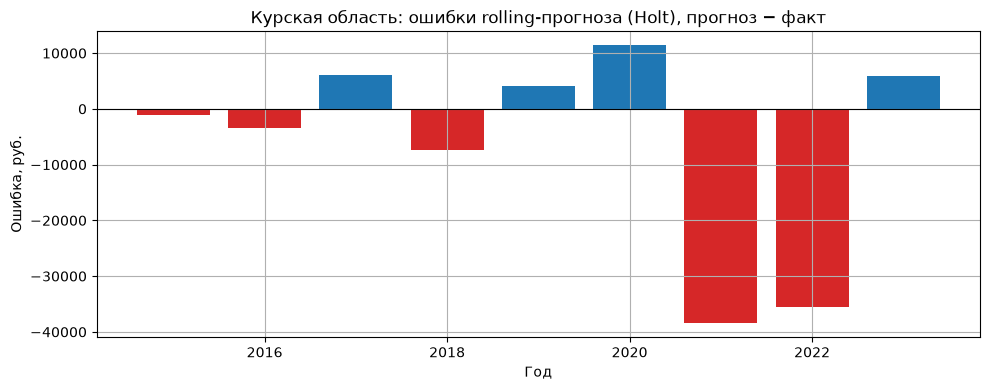

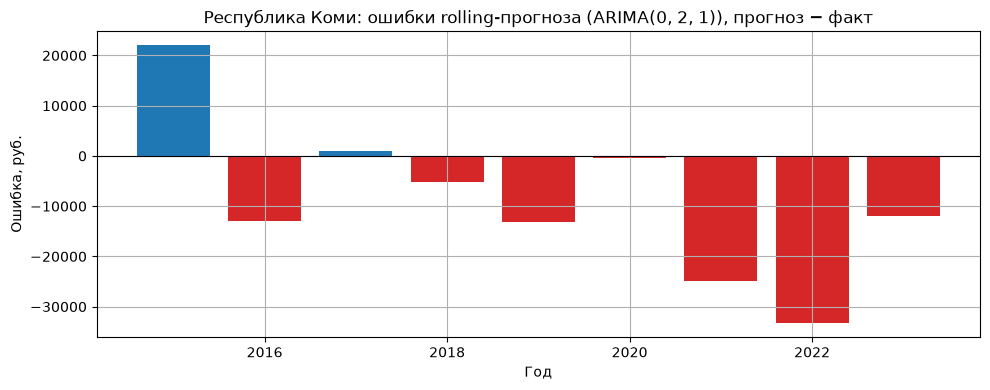

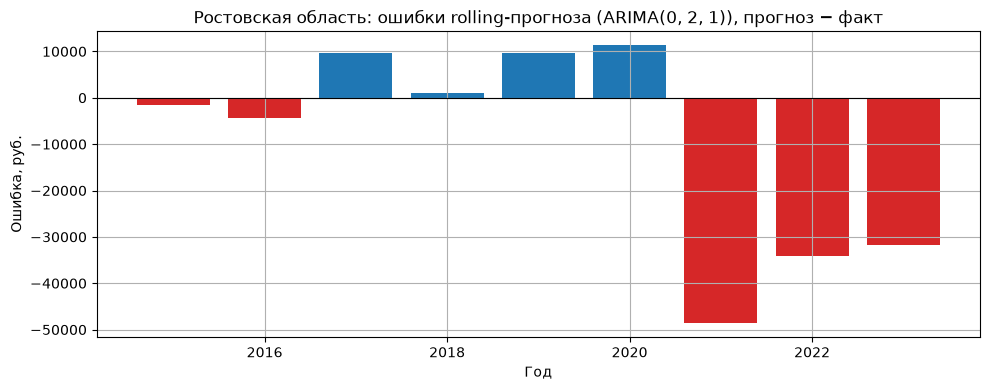

            region          model  year  forecast  actual  error  error_pct
   Курская область           Holt  2021    355941  394357 -38415       -9.7
   Курская область           Holt  2022    407498  442958 -35460       -8.0
   Курская область           Holt  2020    351383  339993  11390        3.3
   Курская область           Holt  2018    303524  310981  -7457       -2.4
   Курская область           Holt  2017    290430  284312   6118        2.2
   Республика Коми ARIMA(0, 2, 1)  2022    504070  537333 -33262       -6.2
   Республика Коми ARIMA(0, 2, 1)  2021    451824  476753 -24929       -5.2
   Республика Коми ARIMA(0, 2, 1)  2015    326469  304462  22007        7.2
   Республика Коми ARIMA(0, 2, 1)  2019    395857  409039 -13182       -3.2
   Республика Коми ARIMA(0, 2, 1)  2016    322377  335386 -13008       -3.9
Ростовская область ARIMA(0, 2, 1)  2021    379872  428455 -48583      -11.3
Ростовская область ARIMA(0, 2, 1)  2022    454180  488204 -34023       -7.0
Ростовская о

In [58]:
error_rows = []
for rname in SELECTED:
    d = fitted[rname]
    c = int(features.loc[rname, 'cluster'])
    err = d['rolling_err']
    top5 = err.abs().sort_values(ascending=False).head(5)
    for yr in top5.index:
        error_rows.append({'region': rname, 'model': best_models[rname],
                           'year': int(yr.year), 'forecast': round(float(d['rolling'].loc[yr, 'pred'])),
                           'actual': round(float(d['rolling'].loc[yr, 'actual'])),
                           'error': round(float(err.loc[yr])),
                           'error_pct': round(float(err.loc[yr] / d['rolling'].loc[yr, 'actual'] * 100), 1)})
    fig, ax = plt.subplots(figsize=(10, 4))
    colors = ['C3' if e < 0 else 'C0' for e in err.values]
    ax.bar([i.year for i in err.index], err.values, color=colors)
    ax.axhline(0, color='black', linewidth=0.8)
    ax.set_title(f'{rname}: ошибки rolling-прогноза ({best_models[rname]}), прогноз − факт')
    ax.set_xlabel('Год'); ax.set_ylabel('Ошибка, руб.')
    plt.tight_layout()
    plt.savefig(FIG / f'errors_{c}.png', dpi=150)
    plt.show()

errors_tbl = pd.DataFrame(error_rows)
errors_sorted = errors_tbl.assign(abs_err=errors_tbl['error'].abs())\
    .sort_values(['region', 'abs_err'], ascending=[True, False]).drop(columns='abs_err')
errors_sorted.to_csv(TAB / 'top_errors.csv', index=False)
SUMMARY['top_errors'] = error_rows
print(errors_sorted.groupby('region').head(5).to_string(index=False))

**Гипотезы о причинах максимальных ошибок** (таблица и графики выше):

- **Курская область (Holt):** топ-2 ошибок — 2021 год (−38,4 тыс. руб., −9,7%) и 2022 год (−35,5 тыс. руб., −8,0%): модель недооценила факт. 2021 год — пост-COVID-восстановление и ускорение инфляции, 2022 год — санкционный шок и инфляция ~12–14%: номинальное потребление росло быстрее тренда. Третья по величине ошибка — 2020 год (+11,4 тыс. руб., +3,3%): модель переоценила, пандемия затормозила потребление.
- **Республика Коми (ARIMA(0,2,1)):** максимальные ошибки — 2022 год (−33,3 тыс. руб., −6,2%) и 2021 год (−24,9 тыс. руб., −5,2%), далее 2015 год (+22,0 тыс. руб., +7,2%). Ошибка 2015 года — отложенный эффект шока конца 2014-го: обвал цен на нефть и девальвация рубля резко подняли инфляцию, а вместе с ней и номинальное потребление сверх тренда, обученного на «спокойных» годах.
- **Ростовская область (ARIMA(0,2,1)):** топ-3 ошибок — 2021 (−48,6 тыс. руб., −11,3%), 2022 (−34,0 тыс. руб., −7,0%) и 2023 (−31,8 тыс. руб., −5,6%): модель систематически недооценивала факт в высокоинфляционные годы. Далее — 2020 год (+11,3 тыс. руб., +3,1%, переоценка из-за пандемии) и 2019 год (+9,7 тыс. руб., +2,7%).

Общая закономерность: модели, обученные на «спокойной» истории, систематически **недооценивают** 2021–2022 годы. В 2021-м потребление в текущих ценах выросло на фоне пост-COVID-восстановления и всплеска инфляции, в 2022-м — на фоне санкционного шока и двузначной инфляции. Статистические модели экстраполируют средний исторический темп прироста и не способны предвидеть инфляционные всплески — это их принципиальное ограничение на данных в текущих ценах. Год 2020 (пандемия COVID-19, падение потребления или его торможение), напротив, модели переоценивают: тренд экстраполировался вверх, а факт оказался ниже. Ошибки 2015 года связаны с шоком конца 2014-го: обвал нефти и рубля, всплеск инфляции до ~13% — потребление в текущих ценах ускорилось относительно тренда.

## Этап 7. Индивидуальные рекомендации

Рекомендации сформулированы для органов региональной экономической политики и основаны на цифрах прогноза каждого региона (прогноз в текущих ценах, поэтому фигурируют темпы прироста показателя, а не реального благосостояния).

In [59]:
# Числовая база для рекомендаций: прогноз лучшей модели и темпы прироста
reco_data = {}
for rname in SELECTED:
    c = int(features.loc[rname, 'cluster'])
    s = fitted[rname]['series']
    best = best_models[rname]
    fc = future_fc[rname]['holt'] if best == 'Holt' else future_fc[rname]['arima']
    g_total = (fc.iloc[-1] / s.iloc[-1] - 1) * 100              # прирост 2026 к 2023, %
    g_year = ((fc.iloc[-1] / s.iloc[-1]) ** (1 / HORIZON) - 1) * 100  # среднегодовой, %
    hist_g = ((s.iloc[-1] / s.iloc[0]) ** (1 / (len(s) - 1)) - 1) * 100
    reco_data[rname] = {'cluster': c, 'model': best,
                        'fc_2026': round(float(fc.iloc[-1])),
                        'growth_2023_2026': round(float(g_total), 1),
                        'growth_per_year': round(float(g_year), 1),
                        'hist_cagr': round(float(hist_g), 1),
                        'value_2023': round(float(s.iloc[-1]))}
    print(f"{rname} (лучшая модель {best}): прогноз 2026 = {fc.iloc[-1]:,.0f} руб., "
          f"прирост к 2023 = {g_total:.1f}% ({g_year:.1f}% в год), исторический CAGR = {hist_g:.1f}%")
SUMMARY['reco'] = reco_data

Курская область (лучшая модель Holt): прогноз 2026 = 590,035 руб., прирост к 2023 = 23.4% (7.3% в год), исторический CAGR = 16.0%
Республика Коми (лучшая модель ARIMA(0, 2, 1)): прогноз 2026 = 756,068 руб., прирост к 2023 = 27.2% (8.3% в год), исторический CAGR = 14.3%
Ростовская область (лучшая модель ARIMA(0, 2, 1)): прогноз 2026 = 803,514 руб., прирост к 2023 = 41.7% (12.3% в год), исторический CAGR = 15.8%


**Курская область (прогноз Holt):**
1. При планировании социальных обязательств бюджета на 2024–2026 гг. закладывать номинальный прирост потребления ≈ 7,3% в год (прогноз 2026 г. — 590,0 тыс. руб. на человека, +23,4% к уровню 2023 г. в 478,0 тыс. руб.). Это вдвое ниже исторического темпа 2000–2023 гг. (16,0% в год) — закладывать «исторические» темпы в план было бы завышением.
2. Так как rolling-анализ показал систематическую недооценку моделью инфляционных всплесков (−9,7% в 2021-м, −8,0% в 2022-м), при повышении инфляции выше 8–9% в год пересматривать план соцподдержки вверх: именно в такие годы фактическое потребление обгоняет прогноз.
3. Использовать прогноз Holt как нижнюю границу сценария: на рядах типа кластера 1 (45 регионов без лет падений) линейный тренд — консервативная оценка; ARIMA даёт более высокие значения (609,7 тыс. руб. на 2026 г., расхождение 3,3%), поэтому диапазон 590–610 тыс. руб. разумно использовать как сценарную вилку.

**Республика Коми (прогноз ARIMA(0,2,1)):**
1. Планировать рост номинального потребления на уровне ≈ 8,3% в год: прогноз 2026 г. — 756,1 тыс. руб. (+27,2% к 594,6 тыс. руб. в 2023 г.). Исторический темп региона (14,3% в год) — самый низкий среди трёх выбранных, поэтому ориентироваться на среднероссийскую динамику при планировании нельзя.
2. Учитывать высокую базу: при максимальном среди выбранных регионов уровне потребления дальнейший рост замедляется; программы поддержки доходов целесообразно фокусировать на реальном, а не номинальном приросте (инфляция «съедает» большую часть номинального роста).
3. Доверять одношаговому прогнозу и ежегодно переобучать модель: rolling-оценка дала MAPE 3,3% против 10,5% на пятилетнем горизонте — на горизонте более 2–3 лет ошибка растёт кратно, прогноз на 2026 г. следует считать ориентиром, а не обязательством.

**Ростовская область (прогноз ARIMA(0,2,1)):**
1. Базовый сценарий: потребление 2026 г. — 803,5 тыс. руб. (+41,7% к 567,0 тыс. руб. в 2023 г., ≈ 12,3% в год). При этом Holt даёт 791,1 тыс. руб. — расхождение моделей менее 2%, прогноз устойчив к выбору спецификации.
2. Регион относится к волатильному кластеру (доля лет падений по кластеру — 4,6%, максимальное падение в среднем −5,3%): при формировании бюджета соцзащиты резервировать средства на годы стагнации, а не экстраполировать только рост.
3. Максимальные ошибки модели приходятся на 2021–2022 гг. (−48,6 и −34,0 тыс. руб.): в условиях инфляционных шоков опираться на оперативные данные Росстата за текущий год и корректировать прогноз, не полагаясь на экстраполяцию.

## Этап 8. Выводы по проекту

В работе выполнен полный цикл анализа временных рядов конечного потребления домашних хозяйств по 79 регионам России за 2000–2023 гг.

**Кластеризация** (иерархическая, метод Уорда, k = 3, silhouette = 0,327) выделила три типа динамики: (1) 45 регионов со стабильным монотонным ростом и средним уровнем потребления (~198 тыс. руб.); (2) 19 регионов с высоким уровнем (~240 тыс. руб.) и самым медленным ростом (14,6% в год) — в основном Москва, северные ресурсные и крупные промышленные регионы; (3) 15 регионов с волатильной динамикой и годами падений.

**Прогнозирование.** Для кластера 1 (стабильный монотонный рост) лучшей оказалась модель Холта (MAPE 6,0% на тесте); для кластеров 2 (замедляющийся рост с высокой базы) и 3 (волатильная динамика) — ARIMA(0,2,1) (MAPE 10,5% и 9,0% соответственно). Все модели в 2–3,3 раза превосходят наивный бейзлайн (MAPE 19–22%). Rolling-оценка показала, что одношаговые прогнозы с переобучением существенно точнее (MAPE 3,3–3,9%), то есть модели устойчивы к обновлению данных, а точность быстро падает с ростом горизонта. Главный фактор ошибок — инфляционные шоки 2021–2022 гг., не предсказуемые статистическими моделями на данных в текущих ценах.

**Ограничения исследования:**
1. Данные в текущих ценах — прогноз отражает номинальную динамику (потребление + инфляция); для выводов об уровне жизни нужен пересчёт в сопоставимые цены (дефлирование ИПЦ по регионам).
2. Короткие ряды (24 наблюдения) ограничивают класс применимых моделей и точность оценки параметров; доверительные интервалы прогнозов широки.
3. Модели не учитывают экзогенные факторы (цены на нефть, санкции, демографию, бюджетные трансферты) — шоки 2020 и 2022 годов предсказуемо дают максимальные ошибки.
4. Шесть территорий исключены из-за пропусков, в т.ч. три автономных округа с высокими доходами (Ненецкий, Ханты-Мансийский и Ямало-Ненецкий) — выборка смещена в сторону «обычных» регионов.
5. В данных есть аномалия (Красноярский край, 2004 г.), не исправленная из-за отсутствия внешнего источника.

**Направления улучшения:** переход к реальным (дефлированным) показателям; добавление экзогенных регрессоров (SARIMAX/динамическая регрессия); панельные и иерархические модели прогнозирования с «заимствованием силы» у похожих регионов; бутстрэп-интервалы прогнозов; проверка моделей машинного обучения (градиентный бустинг по лагам) с честной временной валидацией.

In [60]:
# Сохраняем сводку ключевых чисел для автоматической сборки отчёта
with open(RESULTS / 'summary.json', 'w', encoding='utf-8') as f:
    json.dump(SUMMARY, f, ensure_ascii=False, indent=2, default=str)
print('summary.json сохранён. Ключи:', sorted(SUMMARY.keys()))

summary.json сохранён. Ключи: ['adf', 'arima_orders', 'best_models', 'cluster_1_members', 'cluster_2_members', 'cluster_3_members', 'cluster_profile', 'excluded_agg', 'excluded_fo', 'excluded_missing', 'future', 'metrics', 'n_regions_final', 'n_regions_raw', 'n_total_records', 'reco', 'rep_stats', 'reps_distance', 'rolling', 'selected', 'silhouette', 'top_errors']
